# ¿Hasta qué punto podemos confiar en AlphaFold?
## Análisis computacional de estructuras proteicas y evaluación de la incertidumbre de las predicciones

**Bioinformática · Grado en Ciencia e Ingeniería de Datos · 4.º curso**

**Equipo:** _(nombres)_

**Proteínas analizadas**

| | Proteína | UniProt | Modelo AlphaFold DB |
|---|---|---|---|
| Referencia común | Mioglobina humana | P02144 | AF-P02144-F1 |
| Candidata elegida | Calmodulina humana 1 | P0DP23 | AF-P0DP23-F1 |

**Pregunta orientadora de la candidata:** ¿coinciden la confianza local (pLDDT) y la confianza en la disposición relativa de sus regiones (PAE)?

La mioglobina se usa como caso de comparación, no como verdad experimental ni como control de calidad del modelo.

**Fuentes:** UniProt REST (`rest.uniprot.org`), API de AlphaFold DB (`alphafold.ebi.ac.uk/api/prediction/`) y los archivos PDB y PAE de cada registro. Los identificadores, versiones, URLs y la fecha de acceso se guardan automáticamente en la Fase 2 (tabla `procedencia`).

**Ejecución:** las celdas deben ejecutarse en orden, de arriba abajo (en Colab: *Entorno de ejecución → Ejecutar todas*).

---
# Fase 1. Exploración biológica y estructural

### Fichas de UniProt

| Campo | Mioglobina | Calmodulina-1 |
|---|---|---|
| Identificador | P02144 (gen *MB*) | P0DP23 (gen *CALM1*) |
| Organismo | *Homo sapiens* | *Homo sapiens* |
| Longitud | 154 aa | 149 aa |
| Función | Hemoproteína monomérica que almacena O₂ y facilita su difusión en el tejido muscular. | Sensor de Ca²⁺ que, al unir calcio, regula numerosas enzimas, canales iónicos y otras proteínas. |
| Característica relevante | Dominio globina (2–148); His94 es el ligando proximal del hemo y His65 interviene en la unión de O₂. | Cuatro dominios EF-hand (8–43, 44–79, 81–116, 117–149), cada uno con un sitio de unión de Ca²⁺. Los EF-hand 1-2 forman el lóbulo N y los 3-4 el lóbulo C. |

### Exploración de los modelos en AlphaFold DB (visor 3D coloreado por pLDDT y mapa PAE)

- **Mioglobina:** proteína globular compacta, prácticamente toda en azul oscuro (pLDDT muy alto). Solo el extremo N-terminal (residuo 1) aparece con menor confianza. El mapa PAE es casi uniformemente oscuro (error bajo en toda la matriz).
- **Calmodulina-1:** dos lóbulos de hélices en azul unidos por una zona central de menor confianza (aprox. residuos 74–83). También bajan los extremos N-terminal (aprox. 1–5) y C-terminal (148–149). El mapa PAE muestra **dos bloques diagonales de error bajo** (aprox. 1–75 y 82–149) y bloques fuera de la diagonal con error alto.

Regiones que merecen atención: extremos N y C-terminales de ambas proteínas, y la zona de unión entre lóbulos de la calmodulina (~74–83).

### Hipótesis comprobable

> **H1:** la calmodulina-1 presenta un porcentaje de residuos con pLDDT < 70 claramente mayor que la mioglobina, y esos residuos se concentran en tramos localizados (extremos y zona entre lóbulos), no repartidos a lo largo de la secuencia.

**Indicador para contrastarla:** porcentaje de residuos por banda de pLDDT (Fase 3) y los tramos devueltos por el detector de regiones de baja confianza (Fase 3). La pregunta complementaria sobre la disposición relativa de los lóbulos se contrasta con el PAE en la Fase 4.

---
# Fase 2. Adquisición y procesamiento de datos

In [1]:
# En Google Colab BioPython no viene instalado
%pip install -q biopython

In [2]:
import json
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from Bio.PDB import PDBParser
from Bio.SeqUtils import seq1

pd.set_option("display.max_columns", 30)

PROTEINAS = {
    "P02144": "Mioglobina humana",
    "P0DP23": "Calmodulina humana 1",
}
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

UMBRAL = 70
BANDAS = [  # (etiqueta, límite inferior incluido, límite superior excluido)
    ("Muy baja (<50)", 0, 50),
    ("Baja (50-70)", 50, 70),
    ("Confiada (70-90)", 70, 90),
    ("Muy alta (>=90)", 90, 101),
]

### 2.1 Consulta a UniProt y a la API de AlphaFold DB

Para cada identificador:
1. Se descarga la secuencia canónica de UniProt.
2. Se consulta la API de AlphaFold DB, que devuelve una lista de registros.
3. Se selecciona el registro que corresponde a la **secuencia canónica completa**: mismo accession, `uniprotStart == 1`, `uniprotEnd == longitud` y secuencia idéntica a la de UniProt.
4. Se descargan el PDB y el PAE **de ese mismo registro**, comprobando los códigos HTTP.

Si la API falla, el código busca en `data/` los archivos descargados a mano desde la ficha de AlphaFold DB (botones *PDB file* y *Predicted aligned error*) y anota esa procedencia alternativa.

In [3]:
def get(url, como="json"):
    # GET con comprobación explícita del código HTTP
    r = requests.get(url, timeout=60)
    print(f"  HTTP {r.status_code}  {url}")
    r.raise_for_status()
    return r.json() if como == "json" else r.content


def uniprot_info(acc):
    d = get(f"https://rest.uniprot.org/uniprotkb/{acc}.json")
    return {
        "accession": d["primaryAccession"],
        "nombre": d["proteinDescription"]["recommendedName"]["fullName"]["value"],
        "organismo": d["organism"]["scientificName"],
        "secuencia": d["sequence"]["value"],
        "longitud": d["sequence"]["length"],
    }


def seleccionar_modelo(entradas, acc, seq_canonica):
    # Registro que cubre la secuencia canónica completa
    validas = [
        e for e in entradas
        if e.get("uniprotAccession") == acc
        and e.get("uniprotStart") == 1
        and e.get("uniprotEnd") == len(seq_canonica)
        and e.get("uniprotSequence", e.get("sequence")) == seq_canonica
    ]
    if len(validas) != 1:
        raise ValueError(f"{acc}: {len(validas)} registros válidos de {len(entradas)}; revisar manualmente")
    return validas[0]


procedencia, uniprot, archivos = {}, {}, {}
for acc in PROTEINAS:
    print(acc)
    fecha = datetime.now(timezone.utc).isoformat(timespec="seconds")
    up = uniprot_info(acc)
    uniprot[acc] = up
    pdb_path = pae_path = None
    try:
        entradas = get(f"https://alphafold.ebi.ac.uk/api/prediction/{acc}")
        e = seleccionar_modelo(entradas, acc, up["secuencia"])
        pdb_path = DATA_DIR / Path(e["pdbUrl"]).name
        pae_path = DATA_DIR / Path(e["paeDocUrl"]).name
        pdb_path.write_bytes(get(e["pdbUrl"], como="bytes"))
        pae_path.write_bytes(get(e["paeDocUrl"], como="bytes"))
        procedencia[acc] = {
            "modelo": e["modelEntityId"], "version": e.get("latestVersion"),
            "inicio_uniprot": e["uniprotStart"], "fin_uniprot": e["uniprotEnd"],
            "pLDDT_global_API": e.get("globalMetricValue"),
            "pdbUrl": e["pdbUrl"], "paeUrl": e["paeDocUrl"],
            "fecha_acceso_UTC": fecha, "via": "API AlphaFold DB",
        }
    except Exception as err:
        # Procedimiento alternativo: archivos descargados a mano desde la ficha
        print(f"  Fallo de la API ({err}). Se buscan archivos locales en {DATA_DIR}/")
        pdbs = sorted(DATA_DIR.glob(f"AF-{acc}-F1-model_v*.pdb"))
        paes = sorted(DATA_DIR.glob(f"AF-{acc}-F1-predicted_aligned_error_v*.json"))
        if not (pdbs and paes):
            raise FileNotFoundError(f"{acc}: no hay PDB y PAE locales; elegir otra candidata y justificarlo")
        pdb_path, pae_path = pdbs[-1], paes[-1]
        procedencia[acc] = {
            "modelo": f"AF-{acc}-F1", "version": pdb_path.stem.split("_v")[-1],
            "pdbUrl": f"local: {pdb_path}", "paeUrl": f"local: {pae_path}",
            "fecha_acceso_UTC": fecha, "via": "descarga manual desde la ficha de AlphaFold DB",
        }
    archivos[acc] = {"pdb": pdb_path, "pae": pae_path}

pd.DataFrame(procedencia).T

P02144
  HTTP 200  https://rest.uniprot.org/uniprotkb/P02144.json
  HTTP 200  https://alphafold.ebi.ac.uk/api/prediction/P02144
  HTTP 200  https://alphafold.ebi.ac.uk/files/AF-P02144-F1-model_v6.pdb
  HTTP 200  https://alphafold.ebi.ac.uk/files/AF-P02144-F1-predicted_aligned_error_v6.json
P0DP23
  HTTP 200  https://rest.uniprot.org/uniprotkb/P0DP23.json
  HTTP 200  https://alphafold.ebi.ac.uk/api/prediction/P0DP23
  HTTP 200  https://alphafold.ebi.ac.uk/files/AF-P0DP23-F1-model_v6.pdb
  HTTP 200  https://alphafold.ebi.ac.uk/files/AF-P0DP23-F1-predicted_aligned_error_v6.json


,modelo,version,inicio_uniprot,fin_uniprot,pLDDT_global_API,pdbUrl,paeUrl,fecha_acceso_UTC,via
P02144,AF-P02144-F1,6,1,154,97.19,https://alphafold.ebi.ac.uk/files/AF-P02144-F1...,https://alphafold.ebi.ac.uk/files/AF-P02144-F1...,2026-11-27T12:05:56+00:00,API AlphaFold DB
P0DP23,AF-P0DP23-F1,6,1,149,85.25,https://alphafold.ebi.ac.uk/files/AF-P0DP23-F1...,https://alphafold.ebi.ac.uk/files/AF-P0DP23-F1...,2026-11-27T12:05:57+00:00,API AlphaFold DB


In [4]:
# Comprobación: los datos corresponden a las proteínas elegidas
pd.DataFrame({
    acc: {"nombre UniProt": u["nombre"], "organismo": u["organismo"], "longitud": u["longitud"],
          "esperado": PROTEINAS[acc]}
    for acc, u in uniprot.items()
}).T

,nombre UniProt,organismo,longitud,esperado
P02144,Myoglobin,Homo sapiens,154,Mioglobina humana
P0DP23,Calmodulin-1,Homo sapiens,149,Calmodulina humana 1


### 2.2 Inspección del archivo PDB

In [5]:
for acc in PROTEINAS:
    lineas = archivos[acc]["pdb"].read_text().splitlines()
    print(f"== {acc} ==")
    print("\n".join(lineas[:2]))
    print("...")
    print("\n".join([l for l in lineas if l.startswith("ATOM")][:4]))
    print()

== P02144 ==
HEADER                                            01-AUG-25                     
TITLE     ALPHAFOLD MONOMER V2.0 PREDICTION FOR MYOGLOBIN (P02144)              
...
ATOM      1  N   MET A   1      13.358  -7.378 -10.719  1.00 65.38           N  
ATOM      2  CA  MET A   1      12.339  -8.213 -10.063  1.00 65.38           C  
ATOM      3  C   MET A   1      11.035  -7.833 -10.722  1.00 65.38           C  
ATOM      4  CB  MET A   1      12.320  -7.965  -8.546  1.00 65.38           C  

== P0DP23 ==
HEADER                                            01-AUG-25                     
TITLE     ALPHAFOLD MONOMER V2.0 PREDICTION FOR CALMODULIN-1 (P0DP23)           
...
ATOM      1  N   MET A   1      13.813   8.382   2.976  1.00 49.16           N  
ATOM      2  CA  MET A   1      12.660   7.503   2.626  1.00 49.16           C  
ATOM      3  C   MET A   1      13.104   6.052   2.551  1.00 49.16           C  
ATOM      4  CB  MET A   1      11.885   7.925   1.361  1.00 49.16        

**Campos de una línea `ATOM` (formato de columnas fijas):**

| Columnas | Campo | Ejemplo (`ATOM 2 CA MET A 1 12.339 -8.213 -10.063 1.00 65.38 C`) |
|---|---|---|
| 13–16 | Nombre del átomo | `CA` (carbono alfa) |
| 18–20 | Residuo | `MET` |
| 22 | Cadena | `A` |
| 23–26 | Número de residuo | `1` |
| 31–54 | Coordenadas x, y, z (Å) | `12.339 -8.213 -10.063` |
| 55–60 | Ocupación | `1.00` |
| 61–66 | Campo B (*B-factor*) | `65.38` |

**¿Por qué el campo B contiene pLDDT?** En una estructura experimental el campo B es el factor de temperatura (desplazamiento atómico). Un modelo predicho no tiene ese dato, y AlphaFold DB reutiliza la columna para guardar el pLDDT (0–100). Así los visores pueden colorear por confianza sin cambiar el formato. **Ojo:** el significado es el inverso: un B alto en cristalografía indica más movilidad; un pLDDT alto indica más confianza.

**¿Por qué extraerlo una sola vez por residuo mediante el Cα?** El pLDDT es una métrica **por residuo**: todos los átomos de un residuo repiten el mismo valor (se comprueba abajo). Si se tomasen todos los átomos, los residuos grandes (Trp, Arg) pesarían más que los pequeños (Gly) en las estadísticas. El Cα existe en todos los aminoácidos y aparece una vez por residuo, de modo que da exactamente un valor por posición.

In [6]:
parser = PDBParser(QUIET=True)

def tabla_ca(pdb_path, acc):
    estructura = parser.get_structure(acc, pdb_path)
    filas, b_por_residuo = [], {}
    for cadena in estructura[0]:
        for res in cadena:
            if res.id[0] != " ":          # descarta heteroátomos/agua (no debería haber)
                continue
            b_por_residuo[(cadena.id, res.id[1])] = {round(a.get_bfactor(), 2) for a in res}
            if "CA" in res:
                ca = res["CA"]
                x, y, z = ca.coord
                filas.append({"cadena": cadena.id, "posicion": res.id[1],
                              "residuo": res.get_resname(),
                              "x": x, "y": y, "z": z, "plddt": ca.get_bfactor()})
    no_constantes = sum(len(v) > 1 for v in b_por_residuo.values())
    return pd.DataFrame(filas), no_constantes


tablas = {}
for acc in PROTEINAS:
    df, no_const = tabla_ca(archivos[acc]["pdb"], acc)
    tablas[acc] = df
    print(f"{acc}: {len(df)} residuos con Cα; residuos con pLDDT distinto entre sus átomos: {no_const}")

tablas["P02144"].head()

P02144: 154 residuos con Cα; residuos con pLDDT distinto entre sus átomos: 0
P0DP23: 149 residuos con Cα; residuos con pLDDT distinto entre sus átomos: 0


,cadena,posicion,residuo,x,y,z,plddt
0,A,1,MET,12.339,-8.213,-10.063,65.38
1,A,2,GLY,9.092,-8.554,-12.036,85.00
2,A,3,LEU,5.795,-10.176,-11.046,97.56
3,A,4,SER,4.215,-12.873,-13.226,97.88
4,A,5,ASP,0.714,-12.342,-14.693,97.69


### 2.3 Controles de calidad de las tablas

In [7]:
def controles(acc):
    df, seq = tablas[acc], uniprot[acc]["secuencia"]
    seq_modelo = "".join(seq1(r) for r in df["residuo"])
    pos = df["posicion"].to_numpy()
    return {
        "cadenas": ",".join(df["cadena"].unique()),
        "n_residuos": len(df),
        "longitud_UniProt": len(seq),
        "posiciones_duplicadas": int(df["posicion"].duplicated().sum()),
        "rango_posiciones": f"{pos.min()}-{pos.max()}",
        "numeracion_continua": bool(np.all(np.diff(pos) == 1)),
        "pLDDT_min": df["plddt"].min(),
        "pLDDT_max": df["plddt"].max(),
        "pLDDT_en_[0,100]": bool(df["plddt"].between(0, 100).all()),
        "secuencia_identica_a_UniProt": seq_modelo == seq,
    }

qc = pd.DataFrame({acc: controles(acc) for acc in PROTEINAS}).T
qc

,cadenas,n_residuos,longitud_UniProt,posiciones_duplicadas,rango_posiciones,numeracion_continua,pLDDT_min,pLDDT_max,"pLDDT_en_[0,100]",secuencia_identica_a_UniProt
P02144,A,154,154,0,1-154,True,65.38,98.81,True,True
P0DP23,A,149,149,0,1-149,True,41.81,95.88,True,True


In [8]:
# Si algún control falla, el notebook se detiene aquí para documentar la discrepancia antes de seguir
for acc, f in qc.iterrows():
    assert f["posiciones_duplicadas"] == 0, f"{acc}: posiciones duplicadas"
    assert f["pLDDT_en_[0,100]"], f"{acc}: pLDDT fuera de rango"
    assert f["n_residuos"] == f["longitud_UniProt"], f"{acc}: cobertura incompleta"
    assert f["secuencia_identica_a_UniProt"], f"{acc}: la secuencia del modelo no coincide con UniProt"
print("Controles superados: cadena única, sin duplicados, pLDDT en [0, 100] y cobertura completa de la secuencia canónica.")

Controles superados: cadena única, sin duplicados, pLDDT en [0, 100] y cobertura completa de la secuencia canónica.


**Resultado de los controles:** ambos modelos tienen una sola cadena (A), un Cα por residuo, numeración continua 1–N y una secuencia idéntica a la canónica de UniProt (154 y 149 residuos). No se ha detectado ninguna discrepancia, por lo que la posición del residuo en el PDB coincide con la posición en UniProt.

---
# Fase 3. Análisis computacional de pLDDT

### 3.1 Métricas descriptivas

In [9]:
def metricas(df):
    p = df["plddt"]
    m = {"n_residuos": len(p), "media": p.mean(), "mediana": p.median(),
         "desv_tipica": p.std(), "min": p.min(), "max": p.max()}
    for etiqueta, lo, hi in BANDAS:
        m[f"% {etiqueta}"] = 100 * ((p >= lo) & (p < hi)).mean()
    m["% pLDDT<70"] = 100 * (p < UMBRAL).mean()
    return m

tabla_metricas = pd.DataFrame({PROTEINAS[a]: metricas(tablas[a]) for a in PROTEINAS}).T.round(2)
tabla_metricas

,n_residuos,media,mediana,desv_tipica,min,max,% Muy baja (<50),% Baja (50-70),% Confiada (70-90),% Muy alta (>=90),% pLDDT<70
Mioglobina humana,154.0,97.18,98.06,3.94,65.38,98.81,0.00,0.65,1.95,97.4,0.65
Calmodulina humana 1,149.0,85.24,89.38,10.86,41.81,95.88,1.34,8.72,45.64,44.3,10.07


In [10]:
# Comprobación cruzada con las fracciones por banda que publica la API (cuando se usó la API)
for acc in PROTEINAS:
    pv = procedencia[acc].get("pLDDT_global_API")
    if pv is not None:
        print(f"{acc}: media calculada {tablas[acc]['plddt'].mean():.2f} | globalMetricValue API {pv}")

P02144: media calculada 97.18 | globalMetricValue API 97.19
P0DP23: media calculada 85.24 | globalMetricValue API 85.25


### 3.2 Perfil de pLDDT por posición

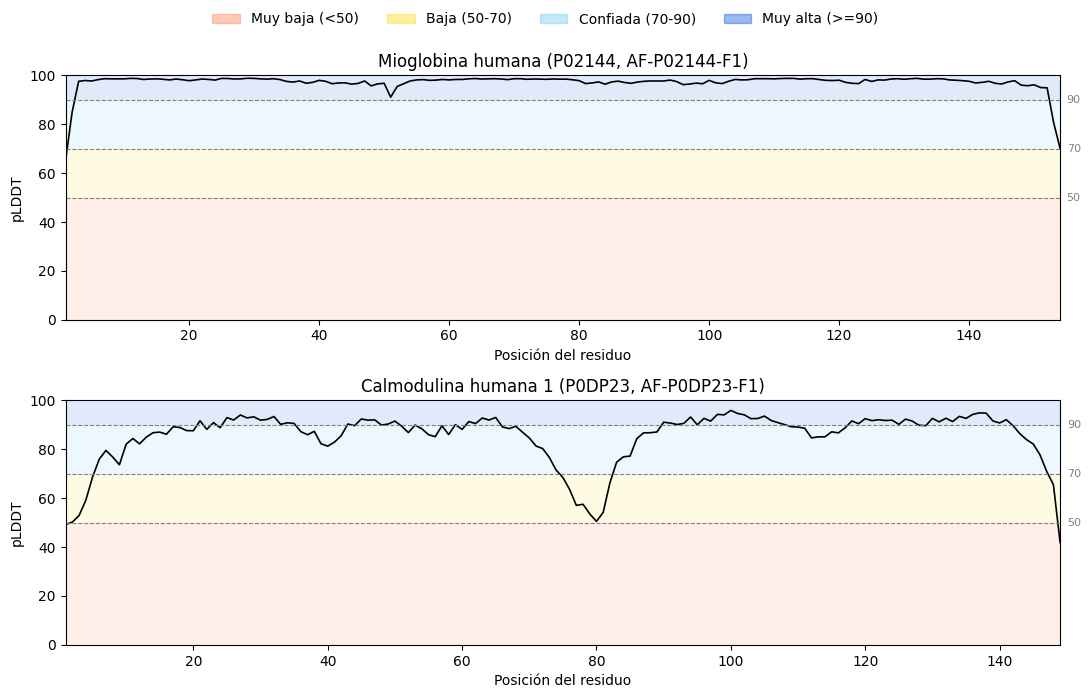

In [11]:
COLORES_BANDA = ["#FF7D45", "#FFDB13", "#65CBF3", "#0053D6"]  # colores del visor de AlphaFold DB

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharey=True)
for ax, acc in zip(axes, PROTEINAS):
    df = tablas[acc]
    for (etiqueta, lo, hi), col in zip(BANDAS, COLORES_BANDA):
        ax.axhspan(lo, min(hi, 100), color=col, alpha=0.12, lw=0)
    ax.plot(df["posicion"], df["plddt"], color="black", lw=1.2)
    for u in (50, 70, 90):
        ax.axhline(u, ls="--", lw=0.8, color="grey")
        ax.text(df["posicion"].max() + 1, u, f"{u}", va="center", fontsize=8, color="grey")
    ax.set_title(f"{PROTEINAS[acc]} ({acc}, {procedencia[acc]['modelo']})")
    ax.set_xlabel("Posición del residuo")
    ax.set_ylabel("pLDDT")
    ax.set_ylim(0, 100)
    ax.set_xlim(1, df["posicion"].max())
handles = [plt.Rectangle((0, 0), 1, 1, color=c, alpha=0.4) for c in COLORES_BANDA]
fig.legend(handles, [b[0] for b in BANDAS], loc="upper center", ncol=4, frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

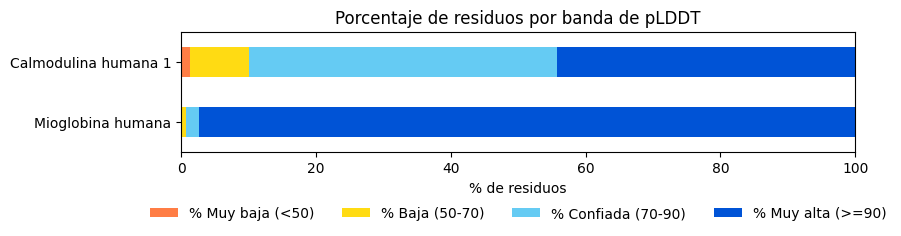

In [12]:
# Distribución en porcentaje (comparable entre proteínas de distinta longitud)
cols = [f"% {b[0]}" for b in BANDAS]
ax = tabla_metricas[cols].plot(kind="barh", stacked=True, color=COLORES_BANDA, figsize=(9, 2.8))
ax.set_xlabel("% de residuos")
ax.set_xlim(0, 100)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.35), ncol=4, frameon=False)
ax.set_title("Porcentaje de residuos por banda de pLDDT")
plt.tight_layout()
plt.show()

### 3.3 Detector de tramos de baja confianza

Reglas de la función:
- Un tramo son **al menos 3 residuos consecutivos** con pLDDT **< 70**.
- Lo interrumpe un valor **≥ 70** o un **salto en la numeración** (posición ≠ anterior + 1).
- Se cierra también un tramo que llegue al **final de la secuencia**.
- Devuelve una lista de intervalos `(inicio, fin)`, ambos incluidos, en numeración de residuo.

In [13]:
def detectar_tramos(posiciones, valores, umbral=70, min_len=3):
    # Devuelve [(inicio, fin), ...] de tramos con valores < umbral y longitud >= min_len
    tramos = []
    inicio = anterior = None
    longitud = 0
    for p, v in zip(posiciones, valores):
        consecutivo = anterior is not None and p == anterior + 1
        if v < umbral:
            if inicio is not None and consecutivo:
                longitud += 1                     # el tramo sigue
            else:
                if inicio is not None and longitud >= min_len:
                    tramos.append((inicio, anterior))   # un salto cierra el tramo previo
                inicio, longitud = p, 1           # empieza uno nuevo
        else:
            if inicio is not None and longitud >= min_len:
                tramos.append((inicio, anterior))
            inicio, longitud = None, 0
        anterior = p
    if inicio is not None and longitud >= min_len:  # tramo al final de la secuencia
        tramos.append((inicio, anterior))
    return tramos


def tramo_mas_largo(tramos):
    return max(tramos, key=lambda t: t[1] - t[0] + 1) if tramos else None

In [14]:
# Prueba 1: intervalos esperados, con un valor igual al umbral, un salto de numeración y un tramo final
pos1 = [1, 2, 3, 4, 5, 6, 7,   10, 11, 12, 13, 14, 15, 16]   # salto 7 -> 10
val1 = [90, 60, 55, 40, 70.0, 65, 60,  50, 45, 30, 85, 69.9, 20, 10]
# 2-4: tramo válido | 5 = 70 interrumpe | 6-7 solo 2 residuos y el salto lo corta (no se une con 10)
# 10-12: tramo válido tras el salto | 14-16: tramo que llega al final
esperado1 = [(2, 4), (10, 12), (14, 16)]
assert detectar_tramos(pos1, val1) == esperado1, detectar_tramos(pos1, val1)

# Prueba 2: ningún tramo válido (solo segmentos de 1-2 residuos, incluido uno al final)
pos2 = [1, 2, 3, 4, 5, 6, 7, 8]
val2 = [69, 69, 90, 50, 70, 40, 65, 99]
assert detectar_tramos(pos2, val2) == [], detectar_tramos(pos2, val2)

# Prueba 3 (extra): un salto en medio de valores bajos parte un tramo largo en dos válidos
assert detectar_tramos([1, 2, 3, 5, 6, 7], [10] * 6) == [(1, 3), (5, 7)]
# Prueba 4 (extra): entrada vacía y secuencia entera por debajo del umbral
assert detectar_tramos([], []) == []
assert detectar_tramos([1, 2, 3, 4], [10, 20, 30, 40]) == [(1, 4)]
print("Todas las pruebas sintéticas superadas.")

Todas las pruebas sintéticas superadas.


In [15]:
resumen_tramos = []
for acc in PROTEINAS:
    df = tablas[acc]
    tramos = detectar_tramos(df["posicion"].tolist(), df["plddt"].tolist(), umbral=UMBRAL)
    largo = tramo_mas_largo(tramos)
    sueltos = sorted(set(df.loc[df["plddt"] < UMBRAL, "posicion"]) -
                     {p for a, b in tramos for p in range(a, b + 1)})
    resumen_tramos.append({
        "proteína": PROTEINAS[acc],
        "tramos (inicio-fin)": ", ".join(f"{a}-{b}" for a, b in tramos) or "ninguno",
        "tramo más largo": f"{largo[0]}-{largo[1]} ({largo[1]-largo[0]+1} res.)" if largo else "no existe",
        "residuos <70 fuera de tramos": sueltos,
    })
pd.DataFrame(resumen_tramos).set_index("proteína")

,tramos (inicio-fin),tramo más largo,residuos <70 fuera de tramos
proteína,,,
Mioglobina humana,ninguno,no existe,[1]
Calmodulina humana 1,"1-5, 75-82",75-82 (8 res.),"[148, 149]"


In [16]:
# Detalle de la zona entre lóbulos de la calmodulina
tablas["P0DP23"].query("70 <= posicion <= 90")[["posicion", "residuo", "plddt"]].T

,69,70,71,72,73,74,75,76,77,78,79,80,81,82,83,84,85,86,87,88,89
posicion,70,71,72,73,74,75,76,77,78,79,80,81,82,83,84,85,86,87,88,89,90
residuo,LEU,THR,MET,MET,ALA,ARG,LYS,MET,LYS,ASP,THR,ASP,SER,GLU,GLU,GLU,ILE,ARG,GLU,ALA,PHE
plddt,84.62,81.31,80.25,76.56,71.44,68.44,63.56,57.03,57.47,53.53,50.47,54.16,66.25,74.69,76.88,77.19,84.31,86.69,86.75,87.06,91.06


### 3.4 Interpretación

Valores obtenidos con los modelos v6 (acceso del 27/11/2026):

| | Media | Mediana | % muy alta | % confiada | % baja | % muy baja | % < 70 |
|---|---|---|---|---|---|---|---|
| Mioglobina | 97.18 | 98.06 | 97.4 | 1.9 | 0.6 | 0.0 | 0.6 |
| Calmodulina-1 | 85.24 | 89.38 | 44.3 | 45.6 | 8.7 | 1.3 | 10.1 |

Tramos detectados: **mioglobina, ninguno** (solo el residuo 1 tiene pLDDT < 70, con 65.4). **Calmodulina-1: 1–5 y 75–82**. El más largo es **75–82 (8 residuos)**, con mínimo de 50.5 en el residuo 80. Los residuos 148–149 también están por debajo de 70, pero son solo dos y no forman tramo.

**¿La media refleja adecuadamente la distribución?** En la mioglobina sí: la distribución está concentrada cerca de 98 y media y mediana casi coinciden. En la calmodulina no del todo: la distribución tiene cola hacia valores bajos (media 85.2 < mediana 89.4). La media, por sí sola, da la imagen de un modelo "uniformemente confiado", cuando en realidad el 10 % de los residuos está por debajo de 70 y agrupado en zonas concretas. Por eso hacen falta las bandas y el perfil por posición.

**¿Coinciden las observaciones visuales y computacionales?** Sí. Las zonas amarillas y naranjas del visor 3D (extremo N-terminal, unión entre lóbulos y extremo C-terminal de la calmodulina; residuo 1 de la mioglobina) son las que señala el detector o, en el caso de los extremos de dos residuos o menos, las que quedan por debajo del umbral sin formar tramo. El detector añade límites exactos que a simple vista solo se estiman.

**¿Por qué las posiciones numéricas de proteínas distintas no son necesariamente homólogas?** La numeración solo cuenta residuos desde el extremo N-terminal de cada secuencia. El residuo 75 de la mioglobina y el 75 de la calmodulina no ocupan un lugar equivalente: las proteínas tienen longitudes distintas, pertenecen a familias distintas (globina frente a EF-hand) y nadie ha alineado sus secuencias ni sus estructuras. Para hablar de posiciones equivalentes haría falta un alineamiento previo. Por eso comparamos porcentajes y patrones, no posiciones concretas.

---
# Fase 4. Análisis matricial de PAE

### 4.1 Carga y comprobaciones

El JSON de AlphaFold DB es una lista con un objeto que contiene `predicted_aligned_error` (matriz N×N, en Å) y `max_predicted_aligned_error`. Convención del visor de AlphaFold DB: **fila = residuo alineado, columna = residuo evaluado**. El valor (i, j) es el error esperado en la posición del residuo j cuando predicción y estructura real se superponen sobre el residuo i.

In [17]:
pae, pae_max = {}, {}
for acc in PROTEINAS:
    doc = json.loads(archivos[acc]["pae"].read_text())
    doc = doc[0] if isinstance(doc, list) else doc
    M = np.asarray(doc["predicted_aligned_error"], dtype=float)
    pae[acc], pae_max[acc] = M, doc.get("max_predicted_aligned_error")

chequeo_pae = pd.DataFrame({
    acc: {
        "forma": M.shape,
        "cuadrada": M.ndim == 2 and M.shape[0] == M.shape[1],
        "finitos": bool(np.isfinite(M).all()),
        "no_negativos": bool((M >= 0).all()),
        "dim == n_residuos": M.shape[0] == len(tablas[acc]),
        "min": M.min(), "max": M.max(),
        "max_PAE_declarado": pae_max[acc],
        "media_diagonal": M.diagonal().mean(),
        "max |M - Mᵀ|": np.abs(M - M.T).max(),
        "PAE_medio_global": M.mean(),
    } for acc, M in pae.items()
}).T
chequeo_pae

,forma,cuadrada,finitos,no_negativos,dim == n_residuos,min,max,max_PAE_declarado,media_diagonal,max |M - Mᵀ|,PAE_medio_global
P02144,"(154, 154)",True,True,True,True,0.0,29.0,31.75,0.0,24.0,2.672078
P0DP23,"(149, 149)",True,True,True,True,0.0,31.0,31.75,0.0,19.0,13.281113


In [18]:
for acc, M in pae.items():
    assert M.ndim == 2 and M.shape[0] == M.shape[1], f"{acc}: PAE no cuadrada"
    assert np.isfinite(M).all() and (M >= 0).all(), f"{acc}: valores no válidos"
    assert M.shape[0] == len(tablas[acc]), f"{acc}: dimensión distinta de la longitud del modelo"
    # La numeración del PDB es 1..N continua (Fase 2), por lo que el índice de matriz k es el residuo k+1
    assert (tablas[acc]["posicion"].to_numpy() == np.arange(1, M.shape[0] + 1)).all()
print("PAE: matrices cuadradas, finitas, no negativas y con correspondencia directa índice k -> residuo k+1.")

PAE: matrices cuadradas, finitas, no negativas y con correspondencia directa índice k -> residuo k+1.


La correspondencia con la secuencia es directa: la dimensión coincide con el número de residuos, y la numeración del PDB es 1..N, idéntica a la de UniProt. `max |M − Mᵀ|` es claramente mayor que 0, así que **la matriz no es simétrica**: el error depende de sobre qué residuo se alinea. Por eso no se simetriza.

### 4.2 Mapas de calor con la misma escala

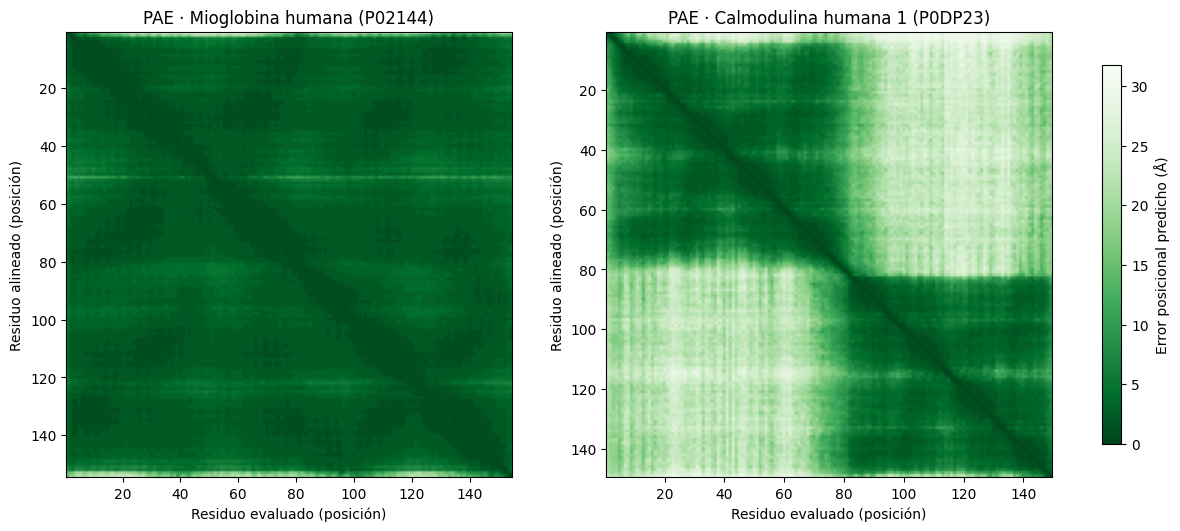

In [19]:
VMAX = max(v for v in pae_max.values() if v is not None)   # misma escala de color para ambas

fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), constrained_layout=True)
for ax, acc in zip(axes, PROTEINAS):
    M = pae[acc]
    n = M.shape[0]
    im = ax.imshow(M, cmap="Greens_r", vmin=0, vmax=VMAX, origin="upper",
                   extent=(0.5, n + 0.5, n + 0.5, 0.5))   # ejes en numeración de residuo 1..N
    ax.set_title(f"PAE · {PROTEINAS[acc]} ({acc})")
    ax.set_xlabel("Residuo evaluado (posición)")
    ax.set_ylabel("Residuo alineado (posición)")
cb = fig.colorbar(im, ax=axes, shrink=0.85)
cb.set_label("Error posicional predicho (Å)")
plt.show()

### 4.3 Análisis regional (calmodulina-1)

Se eligen dos regiones **no solapadas** a partir de las anotaciones de UniProt:
- **Región A, lóbulo N:** EF-hand 1 + EF-hand 2, residuos **8–79**.
- **Región B, lóbulo C:** EF-hand 3 + EF-hand 4, residuos **81–149**.

Se calcula el PAE medio dentro de cada región (A→A, B→B) y entre ellas en las dos direcciones (A→B: alineando sobre A y evaluando B; B→A: al revés).

In [20]:
def bloque(M, filas, columnas):
    # PAE medio del bloque; filas = residuos alineados, columnas = evaluados (numeración 1..N, inclusiva)
    (f0, f1), (c0, c1) = filas, columnas
    return M[f0 - 1:f1, c0 - 1:c1].mean()

ACC = "P0DP23"
REGIONES = {"A (EF-hand 1-2, 8-79)": (8, 79), "B (EF-hand 3-4, 81-149)": (81, 149)}
M, df = pae[ACC], tablas[ACC]
(nA, A), (nB, B) = REGIONES.items()

regional = pd.DataFrame(
    [[bloque(M, A, A), bloque(M, A, B)],
     [bloque(M, B, A), bloque(M, B, B)]],
    index=[f"alineado en {nA}", f"alineado en {nB}"],
    columns=[f"evaluado en {nA}", f"evaluado en {nB}"],
).round(2)
display(regional)

plddt_reg = {n: df.query(f"{a} <= posicion <= {b}")["plddt"].agg(["mean", "min"]).round(2).to_dict()
             for n, (a, b) in REGIONES.items()}
pd.DataFrame(plddt_reg).T.rename(columns={"mean": "pLDDT medio", "min": "pLDDT mínimo"})

,"evaluado en A (EF-hand 1-2, 8-79)","evaluado en B (EF-hand 3-4, 81-149)"
"alineado en A (EF-hand 1-2, 8-79)",4.34,21.49
"alineado en B (EF-hand 3-4, 81-149)",21.08,4.50


,pLDDT medio,pLDDT mínimo
"A (EF-hand 1-2, 8-79)",85.8,53.53
"B (EF-hand 3-4, 81-149)",87.5,41.81


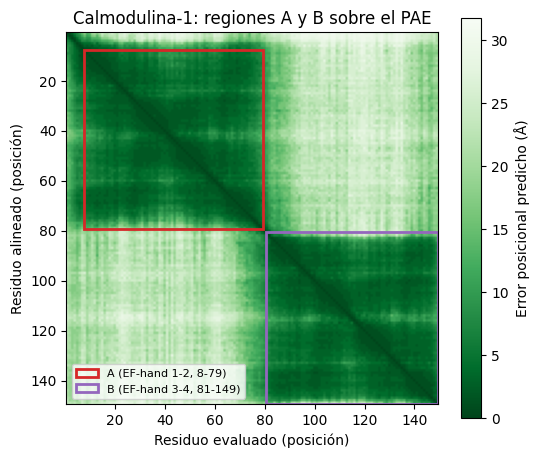

In [21]:
# Visualización: PAE de la calmodulina con las dos regiones marcadas
fig, ax = plt.subplots(figsize=(6, 5.2))
n = M.shape[0]
im = ax.imshow(M, cmap="Greens_r", vmin=0, vmax=VMAX, extent=(0.5, n + 0.5, n + 0.5, 0.5))
for (nombre, (a, b)), col in zip(REGIONES.items(), ["tab:red", "tab:purple"]):
    ax.add_patch(plt.Rectangle((a - 0.5, a - 0.5), b - a + 1, b - a + 1, fill=False, ec=col, lw=2, label=nombre))
ax.set_xlabel("Residuo evaluado (posición)")
ax.set_ylabel("Residuo alineado (posición)")
ax.set_title("Calmodulina-1: regiones A y B sobre el PAE")
ax.legend(loc="lower left", fontsize=8)
fig.colorbar(im, ax=ax, label="Error posicional predicho (Å)")
plt.show()

### 4.4 Interpretación conjunta PAE + pLDDT

Resultados (modelo v6):

| | evaluado en A | evaluado en B |
|---|---|---|
| alineado en A | **4.34 Å** | 21.49 Å |
| alineado en B | 21.08 Å | **4.50 Å** |

pLDDT medio: región A = 85.8, región B = 87.5. PAE medio global: calmodulina 13.3 Å frente a 2.7 Å en la mioglobina.

**¿Es más incierta la disposición relativa que la estructura interna?** Sí, con claridad. Dentro de cada lóbulo el error esperado es de unos 4–5 Å. Al alinear sobre un lóbulo y evaluar el otro sube a unos 21 Å en ambas direcciones, casi cinco veces más. El modelo confía en la geometría interna de cada lóbulo, pero no en dónde queda uno respecto al otro. La asimetría A→B frente a B→A es pequeña (0.4 Å), así que la conclusión no depende de la dirección.

**¿Hay regiones con confianza local alta y posición relativa incierta?** Sí, y la calmodulina es un ejemplo directo. Ambos lóbulos tienen pLDDT medio de 86–88, en la banda "confiada" y con muchos residuos por encima de 90, pero su PAE cruzado ronda los 21 Å. El pLDDT solo baja en la zona de unión (tramo 75–82), y esa caída no basta para anticipar lo grande que es la incertidumbre entre lóbulos. Por tanto, el pLDDT **no** sirve para juzgar la orientación relativa entre dominios: para eso hace falta el PAE. Las distancias o ángulos entre los dos lóbulos del modelo no deberían interpretarse como fiables. En la mioglobina este patrón no aparece: el PAE es bajo en toda la matriz y coincide con un pLDDT alto en casi toda la cadena.

---
# Fase 5. Integración y conclusiones

### Contraste de la hipótesis
**H1 se confirma.** La calmodulina-1 tiene un 10.1 % de residuos con pLDDT < 70, frente al 0.6 % (un solo residuo) de la mioglobina. Esos residuos se agrupan en dos tramos (1–5 y 75–82) y en el extremo C-terminal (148–149), no repartidos por la secuencia.

### Síntesis

Los dos modelos muestran perfiles de confianza muy distintos. La mioglobina, globular y compacta, tiene un pLDDT medio de 97.2, con el 97.4 % de los residuos en la banda muy alta y ningún tramo por debajo de 70. Su PAE es bajo en toda la matriz (2.7 Å de media), así que el modelo confía tanto en la estructura local como en la disposición global.

La calmodulina-1 obtiene una media de 85.2, pero esa cifra oculta una distribución sesgada: la mediana es 89.4, el 10.1 % de los residuos queda por debajo de 70 y el detector señala dos tramos, el N-terminal (1–5) y el de unión entre lóbulos (75–82, el más largo). El PAE muestra lo que el pLDDT no deja ver. Cada lóbulo tiene un error interno de unos 4–5 Å, mientras que el error cruzado ronda los 21 Å en ambas direcciones. Es decir, una confianza local alta convive con una gran incertidumbre en la orientación relativa de los dominios.

Este análisis tiene límites. Solo se estudian dos modelos de una versión concreta (v6), y los números pueden cambiar en versiones futuras. Las regiones se definieron a partir de anotaciones de UniProt, no optimizadas. La calmodulina se modeló aislada y sin Ca²⁺ ni péptidos diana, que en la célula condicionan su conformación.

Por último, pLDDT y PAE son **estimaciones que el propio modelo hace de su error**, no errores medidos. Un pLDDT de 90 significa que AlphaFold espera un buen acuerdo local, no que se haya comprobado. El error real solo puede medirse comparando con una estructura experimental, y aun así depende de las condiciones del experimento y del estado oligomérico o de unión.